# 04 · Factor Investing in NIFTY 50 Stocks — Momentum, Low-Volatility & an India-specific Signal

**Question:** Which stock characteristics have predicted next-month returns among India's largest
companies, and can they be combined into a portfolio that beats the market *after costs*?

Approach (the same toolkit used by systematic equity desks):
* **Signals** computed at each month-end using only data available then.
* **Information Coefficient (IC)** — rank correlation between today's signal and next month's
  return — and its t-statistic. This tests the signal without choosing any portfolio.
* **Quintile portfolios**, long-only top quintile, and top-minus-bottom spread, net of 10 bps costs.
* **Delivery surge** — an India-specific signal from NSE's delivery-volume disclosure (the share
  of traded volume taken into demat, i.e. not intraday speculation).

**Survivorship bias, stated up front:** the universe is *today's* NIFTY 50 (46 names; three listed after
2015 join when they list). Today's members are yesterday's winners, so absolute returns are inflated.
To keep comparisons fair, every factor portfolio is benchmarked against the **equal-weighted
basket of the same 46 stocks**, which carries the identical bias.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src") if (Path.cwd().parent / "src").exists() else "src")

import numpy as np
import pandas as pd
from scipy import stats

from nql import data, metrics
from nql.plotting import PALETTE, plt, save

COST = 0.0010
START = "2016-01-01"
universe = data.NIFTY50  # HDFC Life, SBI Life, IndiGo enter the universe once they list
px = data.panel(universe, start="2015-01-01")
px.loc[:"2015-06-30", "adanient"] = np.nan  # Jun-2015 demerger leaves an unadjusted price break
vol = data.panel(universe, start="2015-01-01", field="Volume")
dlv = data.panel(universe, start="2015-01-01", field="DLV_QTY")
ret = px.pct_change(fill_method=None)
rf = data.risk_free_daily(px.index)
nifty_r = data.nifty().pct_change().reindex(px.index).fillna(0)
print(len(universe), "stocks")

46 stocks


## 1 · Signals (all observable at month-end t)
* **Momentum 12-1:** return from t-12m to t-1m (skip the latest month to avoid short-term reversal).
* **Low volatility:** minus the 252-day daily return volatility.
* **Short-term reversal:** minus the last month's return.
* **Delivery surge (2020+):** last-month delivery % minus its own trailing 12-month average.

In [2]:
me = px.resample("ME").last()
me_idx = me.index
signals = {
    "Momentum 12-1": me.shift(1) / me.shift(12) - 1,
    "Low volatility": -(ret.rolling(252, min_periods=200).std() * np.sqrt(252)).resample("ME").last(),
    "Short-term reversal": -(me / me.shift(1) - 1),
}
dpct = (dlv / vol).where(dlv.notna())
d_m = dpct.resample("ME").mean()
surge = d_m - d_m.rolling(12, min_periods=9).mean()
surge.loc[:"2020-06-29"] = np.nan  # delivery data starts mid-2019
signals["Delivery surge"] = surge
z = {k: v.sub(v.mean(axis=1), axis=0).div(v.std(axis=1), axis=0) for k, v in signals.items()}
signals["Composite (Mom + LowVol)"] = (z["Momentum 12-1"] + z["Low volatility"]) / 2

fwd = (me.shift(-1) / me - 1)  # next-month return (target)
fwd = fwd.loc[START:]

## 2 · Information Coefficients

In [3]:
ic_rows, ic_series = [], {}
for name, sig in signals.items():
    s_ = sig.loc[START:]
    ics = []
    for d in s_.index[:-1]:
        a, b = s_.loc[d], fwd.loc[d]
        m = a.notna() & b.notna()
        if m.sum() >= 20:
            ics.append((d, stats.spearmanr(a[m], b[m]).statistic))
    ic = pd.Series(dict(ics))
    ic_series[name] = ic
    ic_rows.append({"factor": name, "months": len(ic), "mean_IC": ic.mean(), "IC_t_stat": ic.mean() / ic.std() * np.sqrt(len(ic)),
                    "IC_IR_ann": ic.mean() / ic.std() * np.sqrt(12), "pct_months_positive": (ic > 0).mean()})
ic_tab = pd.DataFrame(ic_rows).set_index("factor")
ic_tab.round(3)

,months,mean_IC,IC_t_stat,IC_IR_ann,pct_months_positive
factor,,,,,
Momentum 12-1,128,0.019,0.880,0.269,0.516
Low volatility,128,-0.041,-2.011,-0.616,0.477
Short-term reversal,128,0.052,2.746,0.841,0.578
Delivery surge,75,0.049,2.146,0.858,0.613
Composite (Mom + LowVol),128,-0.006,-0.314,-0.096,0.492


An IC of 0.03-0.05 sounds tiny but is economically large when applied across a portfolio every
month (Grinold's "fundamental law": IR ≈ IC × √breadth). |t| > 2 is the usual bar.

## 3 · Portfolios: daily returns from monthly-rebalanced holdings

In [4]:
def portfolio(weights_m: pd.DataFrame, cost: float = COST) -> pd.Series:
    """weights_m: target weights at month-end; held from the next trading day."""
    w = weights_m.reindex(px.index, method="ffill").shift(1)
    # drift within the month is ignored for simplicity (monthly rebalance to target)
    r = (w * ret.fillna(0)).sum(axis=1)
    turn = weights_m.fillna(0).diff().abs().sum(axis=1).reindex(px.index).fillna(0).shift(1).fillna(0)
    return (r - turn * cost).loc[START:]


def quantile_weights(sig: pd.DataFrame, q: int, n_q: int = 5) -> pd.DataFrame:
    rk = sig.rank(axis=1, pct=True)
    lo, hi = (q - 1) / n_q, q / n_q
    sel = (rk > lo) & (rk <= hi)
    return sel.div(sel.sum(axis=1), axis=0).where(sel.sum(axis=1) > 0)


eq_w = px.resample("ME").last().notna().astype(float)
eq_w = eq_w.div(eq_w.sum(axis=1), axis=0)
ew = portfolio(eq_w)
bench_n = nifty_r.loc[START:]; rf_s = rf.loc[START:]

port_rows, spreads, tops = [], {}, {}
for name, sig in signals.items():
    q_rets = {q: portfolio(quantile_weights(sig, q)) for q in range(1, 6)}
    first = sig.dropna(how="all").index[0]
    rng = slice(max(pd.Timestamp(START), first + pd.offsets.Day(1)), None)
    top, bot = q_rets[5].loc[rng], q_rets[1].loc[rng]
    tops[name], spreads[name] = top, (top - bot)
    ab = metrics.alpha_beta(top, ew.loc[rng], rf_s.loc[rng])
    port_rows.append({"factor": name, "top_q_cagr": metrics.cagr(top), "bottom_q_cagr": metrics.cagr(bot),
                      "ew_universe_cagr": metrics.cagr(ew.loc[rng]), "top_q_sharpe": metrics.sharpe(top, rf_s),
                      "ew_sharpe": metrics.sharpe(ew.loc[rng], rf_s), "top_q_maxdd": metrics.max_dd(top),
                      "alpha_vs_ew": ab["alpha_ann"], "alpha_t": ab["alpha_t"],
                      "quintile_cagrs": [metrics.cagr(q_rets[q].loc[rng]) for q in range(1, 6)]})
fac = pd.DataFrame(port_rows).set_index("factor")
fac.drop(columns="quintile_cagrs").round(3)

,top_q_cagr,bottom_q_cagr,ew_universe_cagr,top_q_sharpe,ew_sharpe,top_q_maxdd,alpha_vs_ew,alpha_t
factor,,,,,,,,
Momentum 12-1,0.215,0.171,0.192,0.782,0.828,-0.442,0.011,0.377
Low volatility,0.121,0.292,0.183,0.501,0.785,-0.273,-0.022,-0.989
Short-term reversal,0.241,0.118,0.183,0.914,0.785,-0.384,0.046,1.557
Delivery surge,0.283,0.122,0.237,1.296,1.181,-0.180,0.039,1.267
Composite (Mom + LowVol),0.156,0.254,0.192,0.623,0.828,-0.369,-0.015,-0.573


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


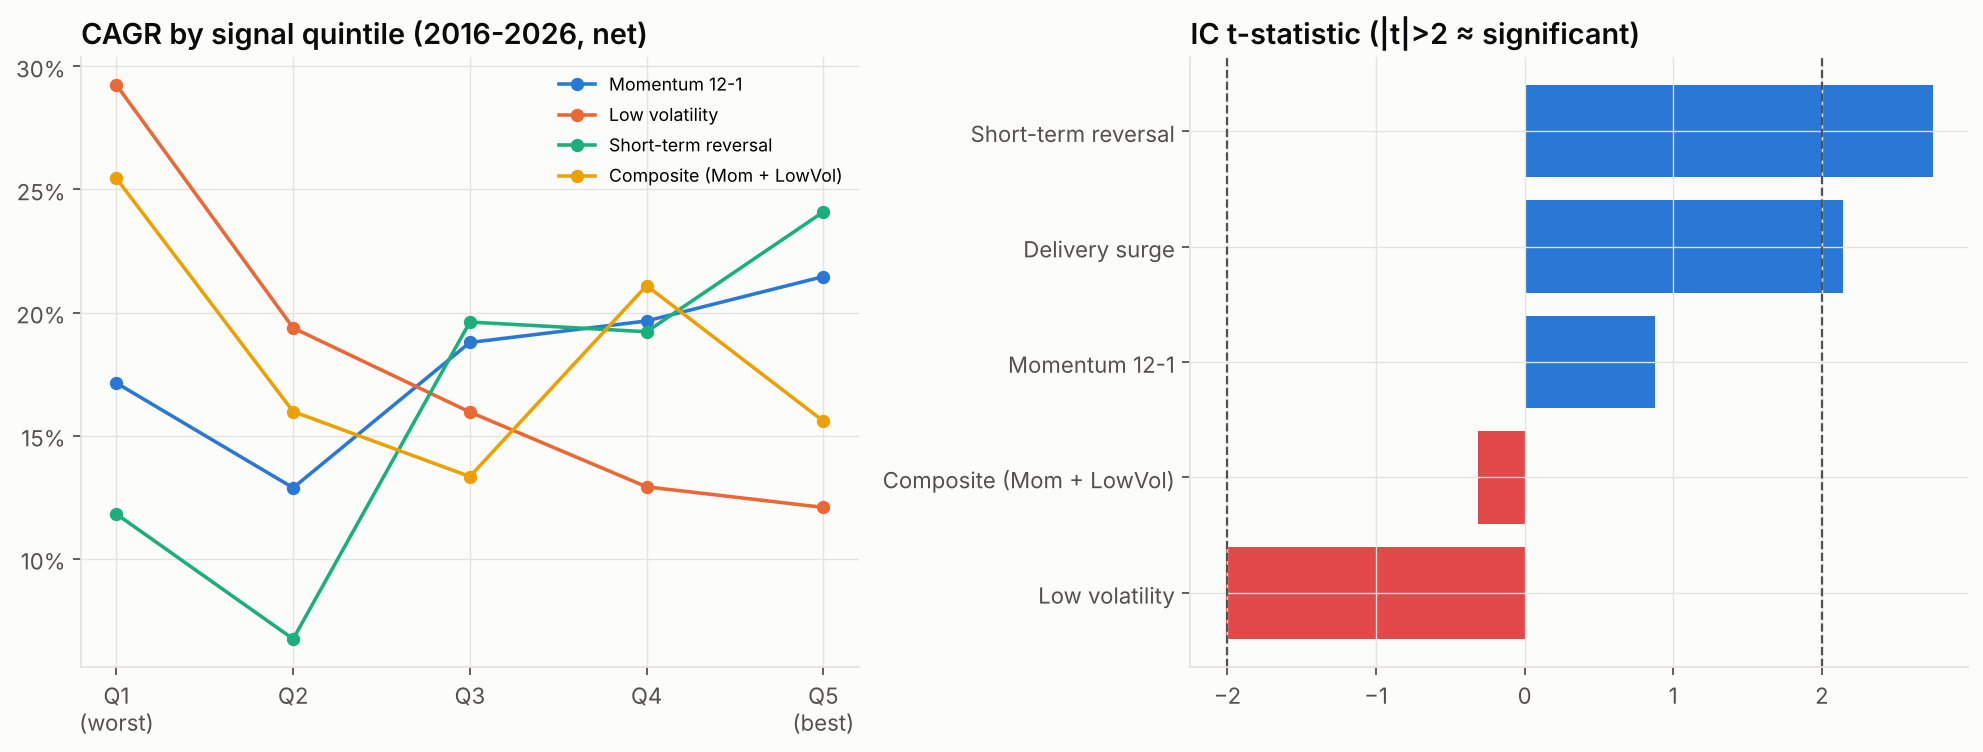

PosixPath('/home/claude/nse-quant-lab/reports/figures/04_factor_quintiles.png')

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))
names = ["Momentum 12-1", "Low volatility", "Short-term reversal", "Composite (Mom + LowVol)"]
x = np.arange(5)
for i, n in enumerate(names):
    axes[0].plot(x + 1, fac.loc[n, "quintile_cagrs"], marker="o", ms=5, color=PALETTE[i], label=n)
axes[0].set_xticks(x + 1, ["Q1\n(worst)", "Q2", "Q3", "Q4", "Q5\n(best)"])
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[0].set_title("CAGR by signal quintile (2016-2026, net)"); axes[0].legend(fontsize=8)
order = ic_tab.sort_values("IC_t_stat").index
axes[1].barh(order, ic_tab.loc[order, "IC_t_stat"], color=[PALETTE[0] if v > 0 else PALETTE[7] for v in ic_tab.loc[order, "IC_t_stat"]])
axes[1].axvline(2, color="#52514e", ls="--", lw=1); axes[1].axvline(-2, color="#52514e", ls="--", lw=1)
axes[1].set_title("IC t-statistic (|t|>2 ≈ significant)")
save(fig, "04_factor_quintiles")

## 4 · The pre-registered composite failed — and why

The Momentum + Low-Vol composite was chosen *before* looking at results, from the global
literature (Jegadeesh-Titman momentum; Frazzini-Pedersen "betting against beta"). In this sample
it did **not** work, because low volatility was *inverted*: the most volatile stocks earned the most.

Part of that is a survivorship artefact: a volatile stock that is in today's NIFTY 50 (Trent, BEL,
Adani Ports, Shriram Finance...) almost by definition had a spectacular run. Section 5 checks the
factors on NSE's official, survivorship-free factor indices.

## 5 · Survivorship-free reality check: NSE's own factor indices

These indices are rebalanced by NSE using point-in-time constituents, so they carry no hindsight.
Each is compared with its parent index over the window where both have data.

In [6]:
checks = [("NIFTY50 Equal Weight", "nifty50 equal weight", "nifty 50"),
          ("NIFTY100 Low Volatility 30", "nifty100 low volatility 30", "nifty 100"),
          ("NIFTY200 Momentum 30", "nifty200 momentum 30", "nifty 200"),
          ("NIFTY200 Quality 30", "nifty200 quality 30", "nifty 200"),
          ("NIFTY Alpha 50", "nifty alpha 50", "nifty 200"),
          ("NIFTY50 Value 20", "nifty50 value 20", "nifty 50")]
idx_rows = []
for label, f, parent in checks:
    a = data.load(f); b = data.load(parent)
    j = a.index.intersection(b.index)
    ra, rb = a.reindex(j).pct_change().dropna(), b.reindex(j).pct_change().dropna()
    rf_j = data.risk_free_daily(ra.index)
    ab = metrics.alpha_beta(ra, rb, rf_j)
    idx_rows.append({"index": label, "parent": parent.upper(), "from": str(ra.index[0].date()),
                     "years": len(ra) / 252, "cagr": metrics.cagr(ra), "parent_cagr": metrics.cagr(rb),
                     "sharpe": metrics.sharpe(ra, rf_j), "parent_sharpe": metrics.sharpe(rb, rf_j),
                     "max_dd": metrics.max_dd(ra), "parent_max_dd": metrics.max_dd(rb),
                     "beta": ab["beta"], "alpha": ab["alpha_ann"], "alpha_t": ab["alpha_t"]})
idx_tab = pd.DataFrame(idx_rows).set_index("index")
idx_tab.round(3)

,parent,from,years,cagr,parent_cagr,sharpe,parent_sharpe,max_dd,parent_max_dd,beta,alpha,alpha_t
index,,,,,,,,,,,,
NIFTY50 Equal Weight,NIFTY 50,2017-04-19,9.278,0.117,0.106,0.432,0.371,-0.413,-0.384,0.959,0.013,0.806
NIFTY100 Low Volatility 30,NIFTY 100,2016-07-12,10.028,0.110,0.109,0.439,0.390,-0.310,-0.381,0.787,0.011,0.675
NIFTY200 Momentum 30,NIFTY 200,2020-08-26,5.992,0.165,0.146,0.617,0.647,-0.318,-0.181,1.169,0.008,0.228
NIFTY200 Quality 30,NIFTY 200,2018-04-19,8.290,0.093,0.108,0.318,0.383,-0.295,-0.382,0.791,-0.003,-0.120
NIFTY Alpha 50,NIFTY 200,2012-11-20,13.544,0.204,0.122,0.734,0.448,-0.407,-0.382,1.061,0.074,2.271
NIFTY50 Value 20,NIFTY 50,2015-11-10,10.671,0.115,0.106,0.429,0.368,-0.312,-0.384,0.848,0.016,0.750


**Measuring the survivorship bias directly.** Same window, same weighting scheme (equal weight,
periodic rebalance): today's members vs NSE's point-in-time NIFTY50 Equal Weight index.

In [7]:
nifty_ew_px = data.load("nifty50 equal weight")
w0 = max(pd.Timestamp(START), nifty_ew_px.index[0] + pd.offsets.MonthBegin(1))  # first full month with index data
nifty_ew_r = nifty_ew_px.reindex(px.index).ffill().pct_change().loc[w0:]
surv = {"window_start": str(w0.date()), "window_end": str(px.index[-1].date()),
        "ew_current_members_cagr": metrics.cagr(ew.loc[w0:]), "nifty50_ew_index_cagr": metrics.cagr(nifty_ew_r),
        "nifty50_cagr": metrics.cagr(bench_n.loc[w0:])}
surv["bias_pp_per_year"] = surv["ew_current_members_cagr"] - surv["nifty50_ew_index_cagr"]
pd.Series(surv)

window_start               2017-05-01
window_end                 2026-09-25
ew_current_members_cagr      0.181364
nifty50_ew_index_cagr        0.114737
nifty50_cagr                 0.104147
bias_pp_per_year             0.066627
dtype: object

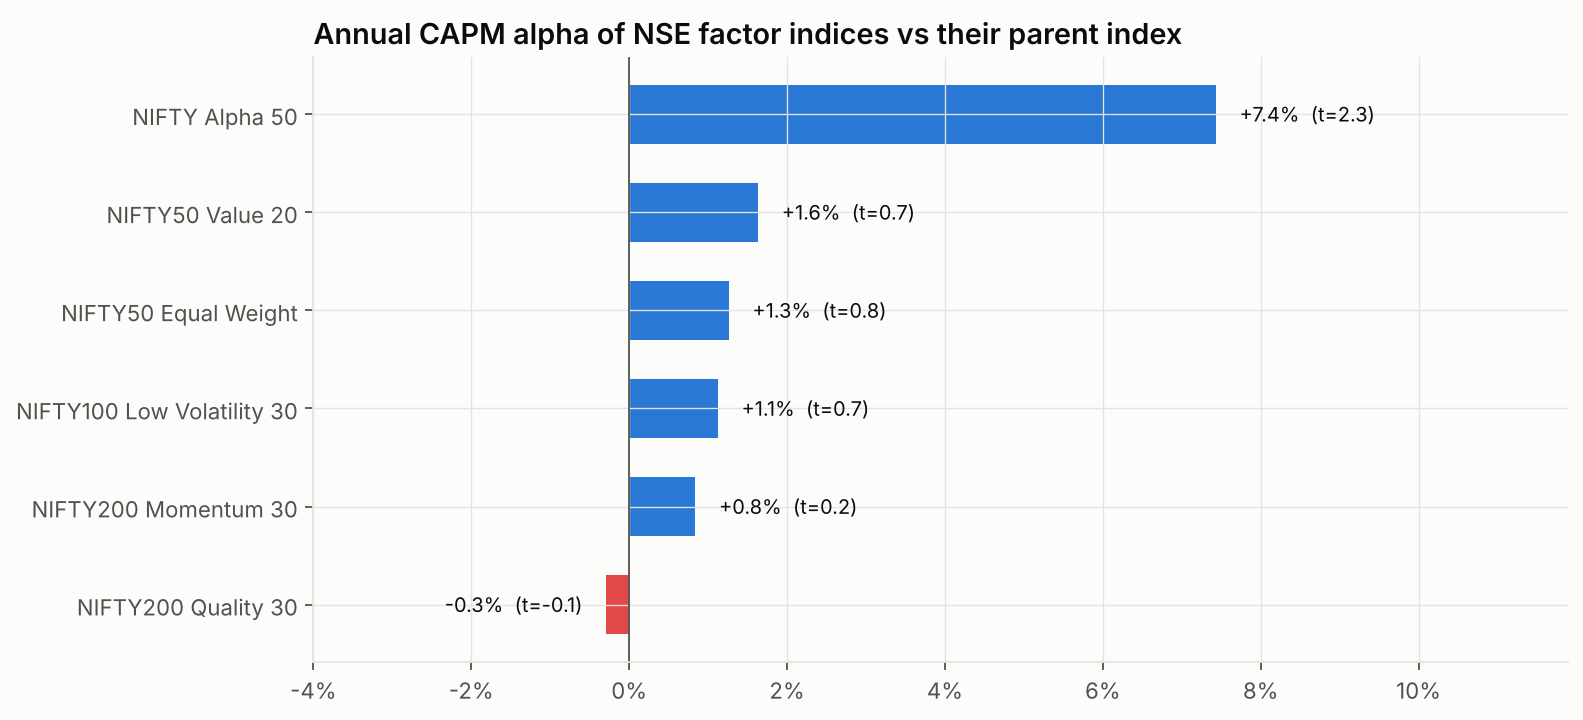

PosixPath('/home/claude/nse-quant-lab/reports/figures/04_nse_factor_indices.png')

In [8]:
fig, ax = plt.subplots(figsize=(10, 4.6))
o = idx_tab.sort_values("alpha").index
cols = [PALETTE[0] if v > 0 else PALETTE[7] for v in idx_tab.loc[o, "alpha"]]
ax.barh(o, idx_tab.loc[o, "alpha"], color=cols, height=0.6)
for i, n in enumerate(o):
    v, t = idx_tab.loc[n, "alpha"], idx_tab.loc[n, "alpha_t"]
    ax.text(v + (0.003 if v >= 0 else -0.003), i, f"{v:+.1%}  (t={t:.1f})", va="center",
            ha="left" if v >= 0 else "right", fontsize=9, color="#0b0b0b")
ax.axvline(0, color="#52514e", lw=0.8)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlim(min(-0.04, idx_tab["alpha"].min() * 2), idx_tab["alpha"].max() * 1.6)
ax.set_title("Annual CAPM alpha of NSE factor indices vs their parent index")
save(fig, "04_nse_factor_indices")

## 6 · Exploratory: Reversal + Delivery Surge (labelled in-sample)

The two signals with |IC t| > 2 were short-term reversal and delivery surge. Combining them *after*
seeing the results is data-snooping, so we (a) label it exploratory and (b) deflate its Sharpe for
the 6 signal portfolios tried in this module.

In [9]:
expl = (z["Short-term reversal"] + z["Delivery surge"]) / 2
expl_start = "2020-07-01"
strat = portfolio(quantile_weights(expl, 5)).loc[expl_start:]
ew_e, bn_e, rf_e = ew.loc[expl_start:], bench_n.loc[expl_start:], rf_s.loc[expl_start:]
trial_sr = np.array([metrics.sharpe(tops[k].loc[expl_start:], rf_e) for k in tops] + [metrics.sharpe(strat, rf_e)])
ab_ew = metrics.alpha_beta(strat, ew_e, rf_e)
w_last = quantile_weights(expl, 5).iloc[-1]
sig_ = {"psr": metrics.probabilistic_sharpe(strat - rf_e), "dsr": metrics.deflated_sharpe(strat - rf_e, trial_sr),
        "sharpe_ci": metrics.bootstrap_sharpe_ci(strat - rf_e),
        "alpha_vs_ew": ab_ew["alpha_ann"], "alpha_vs_ew_t": ab_ew["alpha_t"],
        "avg_monthly_turnover": float(quantile_weights(expl, 5).fillna(0).diff().abs().sum(axis=1).loc[expl_start:].mean() / 2)}
rows = [metrics.summary(bn_e, rf_e, name="NIFTY 50 index"),
        metrics.summary(ew_e, rf_e, bn_e, name="Equal-weight universe (same stocks)"),
        metrics.summary(strat, rf_e, bn_e, name="Reversal + Delivery, top quintile")]
print(sig_)
metrics.table(rows)[["cagr", "vol", "sharpe", "max_dd", "beta", "alpha_ann", "alpha_t"]]

{'psr': 0.9999246261507132, 'dsr': 0.9939057578875407, 'sharpe_ci': (0.6878750671919526, 2.385778291193156), 'alpha_vs_ew': 0.08122853530027231, 'alpha_vs_ew_t': 2.6454555101080235, 'avg_monthly_turnover': 0.6626666666666668}


,cagr,vol,sharpe,max_dd,beta,alpha_ann,alpha_t
name,,,,,,,
NIFTY 50 index,14.2%,14.2%,0.64,-16.9%,nan,nan%,nan
Equal-weight universe (same stocks),23.7%,14.5%,1.18,-16.6%,0.97,8.4%,4.57
"Reversal + Delivery, top quintile",33.2%,16.0%,1.55,-18.5%,0.94,16.3%,4.40


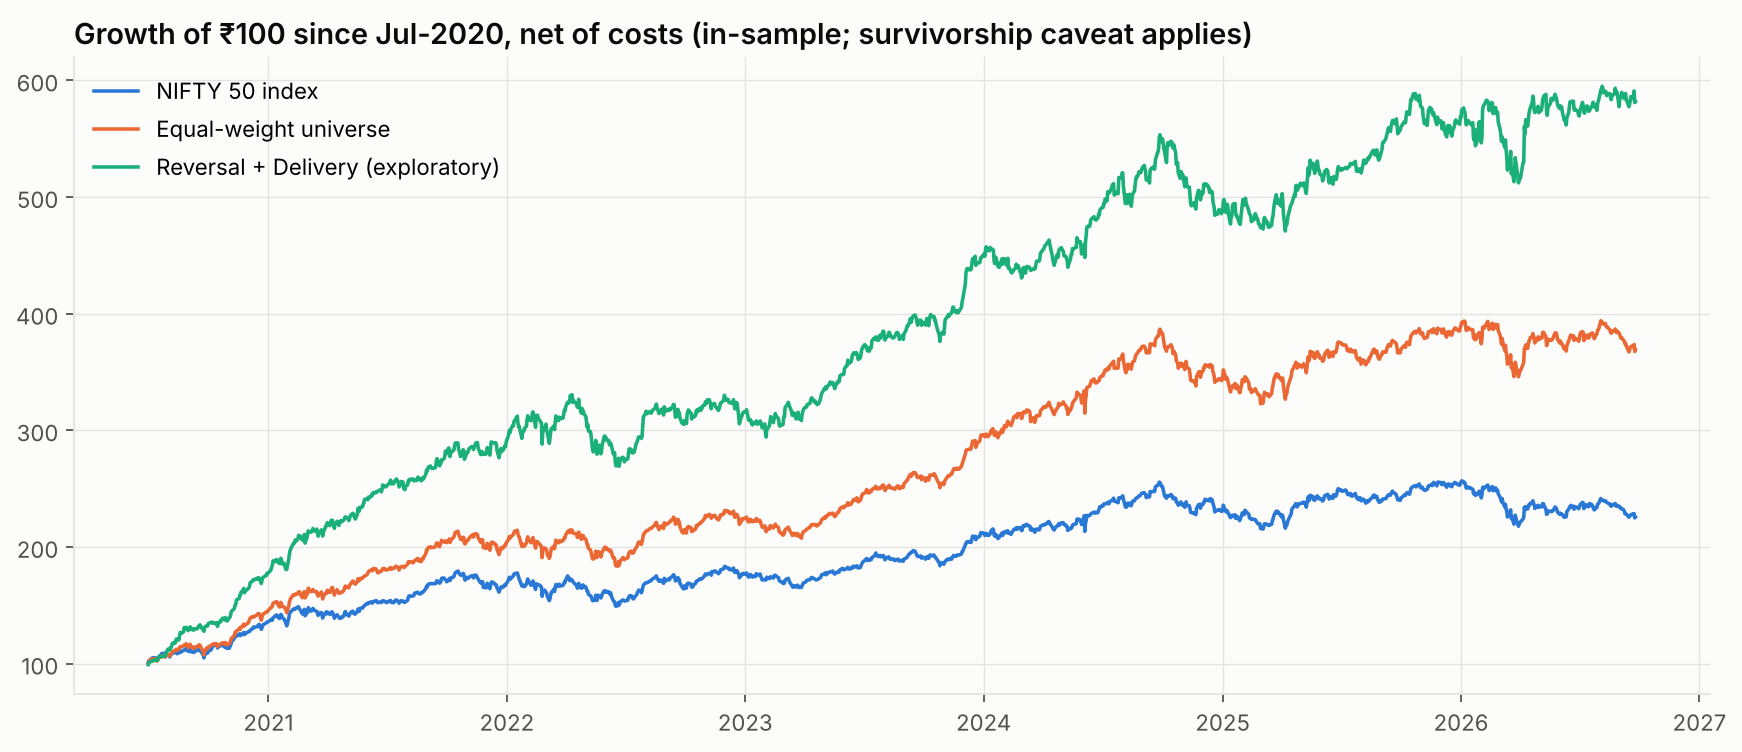

PosixPath('/home/claude/nse-quant-lab/reports/figures/04_exploratory_equity.png')

In [10]:
fig, ax = plt.subplots(figsize=(11, 4.8))
for i, (k, v) in enumerate({"NIFTY 50 index": bn_e, "Equal-weight universe": ew_e, "Reversal + Delivery (exploratory)": strat}.items()):
    w = (1 + v).cumprod() * 100
    ax.plot(w.index, w, color=PALETTE[i], label=k)
ax.legend(); ax.set_title("Growth of ₹100 since Jul-2020, net of costs (in-sample; survivorship caveat applies)")
save(fig, "04_exploratory_equity")

## Takeaways

* **Survivorship bias, measured:** over the same window (May-2017 → Sep-2026, when NSE's index has data), an equal-weight basket of *today's*
  NIFTY 50 names compounded several percentage points a year faster than NSE's point-in-time
  **NIFTY50 Equal Weight** index (see the table in section 5). That gap is pure hindsight — and it is
  larger than most "alphas" a backtest on current constituents would claim. The single most important
  number in this module.
* **Textbook factors were weak in India's large caps.** Momentum's IC was positive but insignificant;
  low-volatility was *inverted*. On NSE's survivorship-free indices, low-vol, quality and value cut
  drawdowns (−31% vs −38%) but produced no significant alpha; only **NIFTY Alpha 50** shows
  significant alpha (~7.4%/yr, t ≈ 2.3) over 13.5 years.
* **Two signals cleared |t| > 2 on IC:** 1-month **reversal** and the India-specific **delivery surge**.
  Combined (exploratory, in-sample, since Jul-2020) the top quintile earned ~8% a year over the
  equal-weight universe (t ≈ 2.6; Deflated Sharpe 0.99 after 6 trials) with ~66% monthly turnover.
  Promising — but it must be paper-traded forward before anyone risks capital on it.

In [11]:
data.save_results("04_factors", {"ic": ic_tab.reset_index().to_dict(orient="records"),
                                 "portfolios": fac.reset_index().to_dict(orient="records"),
                                 "nse_factor_indices": idx_tab.reset_index().to_dict(orient="records"),
                                 "exploratory": rows, "exploratory_stats": sig_, "survivorship": surv, "universe_size": len(universe),
                                 "current_top_quintile": w_last[w_last > 0].index.tolist(),
                                 "as_of": str(px.index[-1].date())})
print("saved")

saved
